In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Загружаем датасет

In [2]:
california_data = fetch_california_housing(as_frame=True)
df = california_data.frame

Первичный анализ

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [10]:
print(df.info())
print(df.shape)
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
(20640, 9)
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333

In [9]:
print(df.isnull().sum())
print(df.duplicated().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
0


Распределение цен

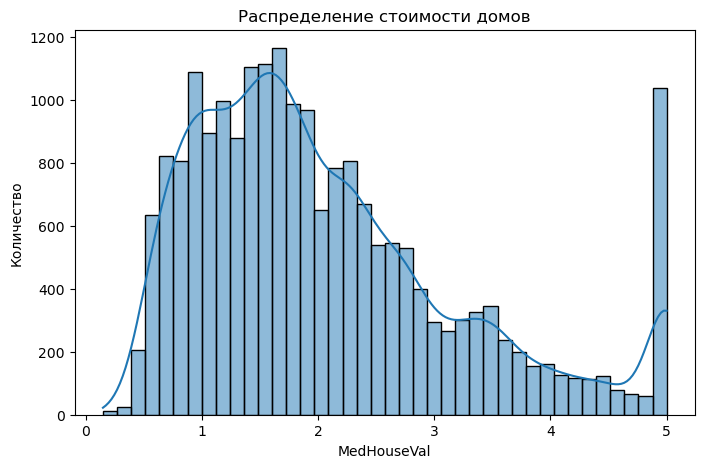

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], bins=40, kde=True)
plt.title('Распределение стоимости домов')
plt.xlabel('MedHouseVal')
plt.ylabel('Количество')
plt.show()

Корелляции

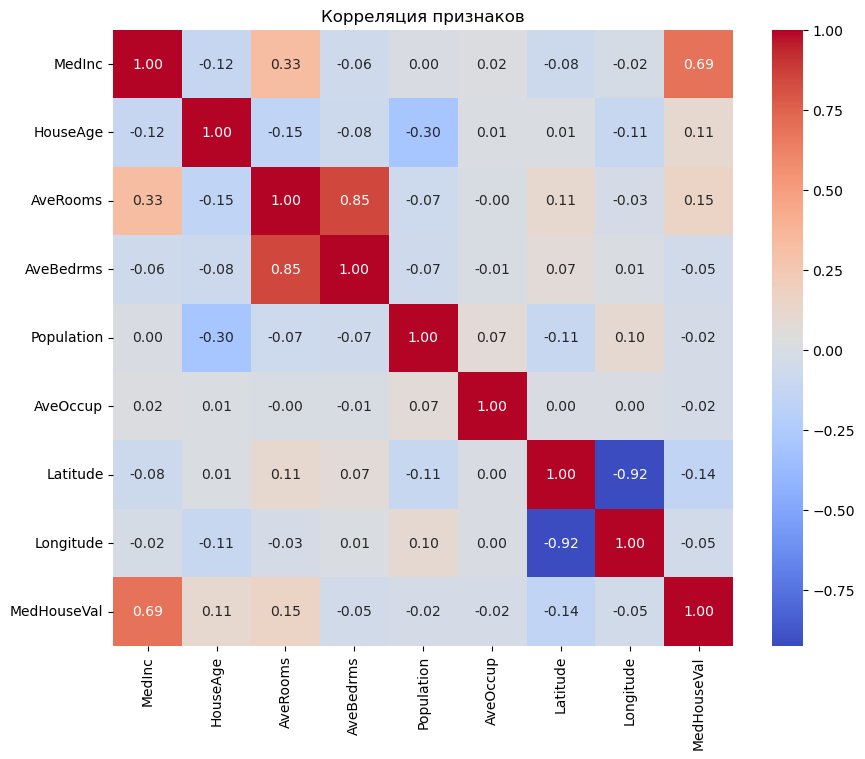

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Корреляция признаков")
plt.show()

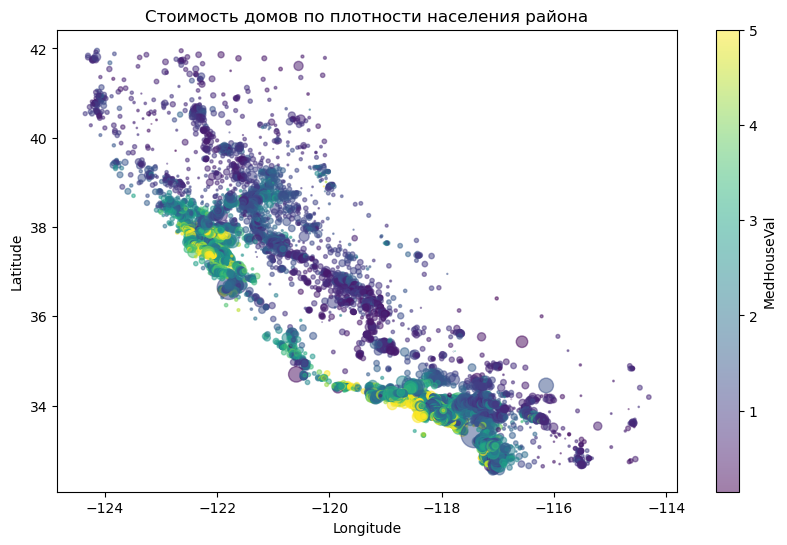

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df['Longitude'],
    df['Latitude'],
    c=df['MedHouseVal'],
    s=df['Population'] / 100,
    alpha=0.5,
    cmap='viridis'
)
plt.colorbar(label='MedHouseVal')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Стоимость домов по плотности населения района')
plt.show()

Машинное обучение

Разделяем признаки и ключевое значение

In [15]:
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [20]:
pred = model.predict(X_test_scaled)

In [21]:
mse = mean_squared_error(y_test, pred)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred)

print("MSE:", round(mse, 4))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2:", round(r2, 4))

MSE: 0.5559
MAE: 0.5332
RMSE: 0.7456
R2: 0.5758


In [22]:
results = pd.DataFrame({
    'Real': y_test.values,
    'Predicted': pred
})

results.head(10)

,Real,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


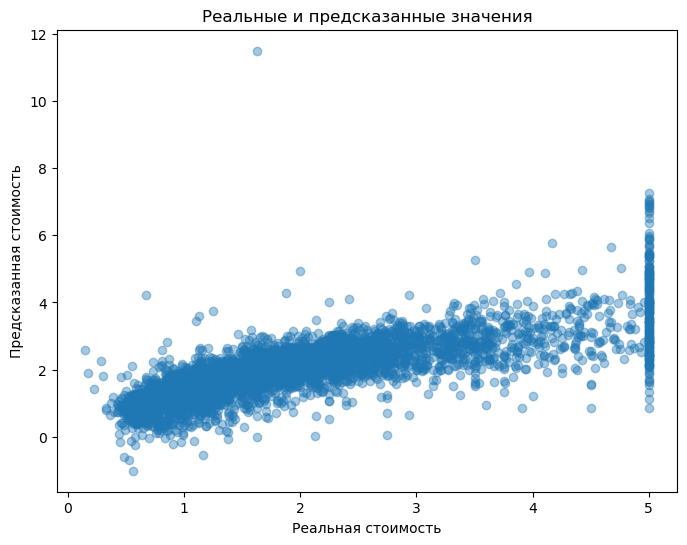

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred, alpha=0.4)
plt.xlabel('Реальная стоимость')
plt.ylabel('Предсказанная стоимость')
plt.title('Реальные и предсказанные значения')
plt.show()